Baseline random forest model


In [ ]:
import numpy as np
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

# ==========================================
# 1. BASELINE RANDOM FOREST CLASSIFIER
# ==========================================

# Generate synthetic classification data
X_clf, y_clf = make_classification(n_samples=1000, n_features=20, random_state=42)

# Split into training and testing sets (80/20 split)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42
)

# Instantiate the baseline classifier with default parameters
# random_state ensures reproducibility across runs
clf_baseline = RandomForestClassifier(random_state=42)

# Train (fit) the model
clf_baseline.fit(X_train_c, y_train_c)

# Predict on the test set
y_pred_clf = clf_baseline.predict(X_test_c)

# Evaluate baseline classification performance
clf_accuracy = accuracy_score(y_test_c, y_pred_clf)
print(f"Baseline Classifier Accuracy: {clf_accuracy:.4f}")


# ==========================================
# 2. BASELINE RANDOM FOREST REGRESSOR
# ==========================================

# Generate synthetic regression data
X_reg, y_reg = make_regression(n_samples=1000, n_features=10, noise=0.1, random_state=42)

# Split into training and testing sets (80/20 split)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Instantiate the baseline regressor with default parameters
reg_baseline = RandomForestRegressor(random_state=42)

# Train (fit) the model
reg_baseline.fit(X_train_r, y_train_r)

# Predict on the test set
y_pred_reg = reg_baseline.predict(X_test_r)

# Evaluate baseline regression performance
reg_rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_reg))
reg_r2 = r2_score(y_test_r, y_pred_reg)

print(f"Baseline Regressor RMSE: {reg_rmse:.4f}")
print(f"Baseline Regressor R² Score: {reg_r2:.4f}")


Testing Distribution of sample means and sample variances.

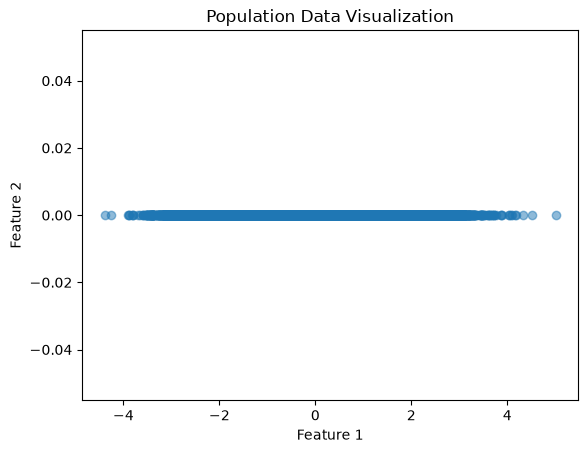

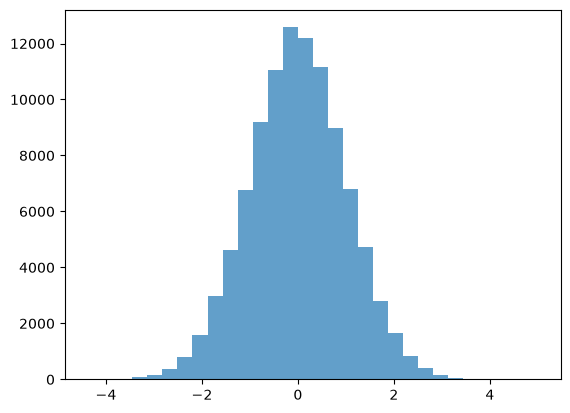

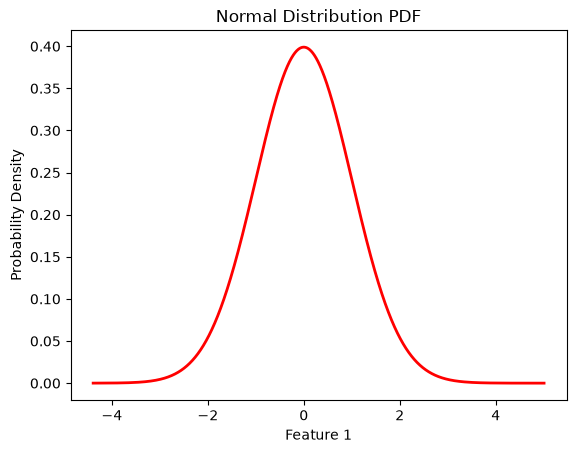

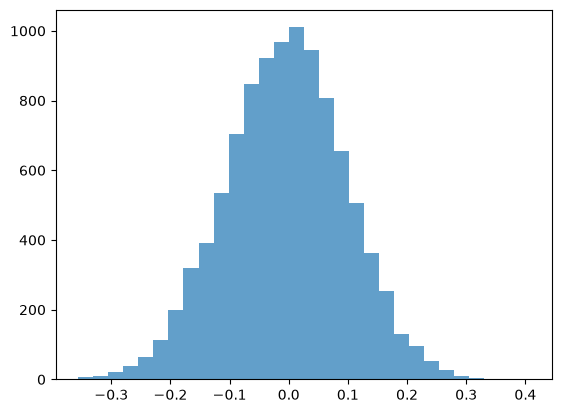

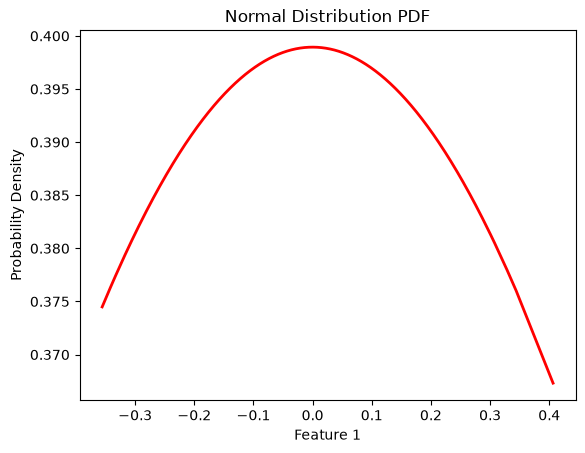

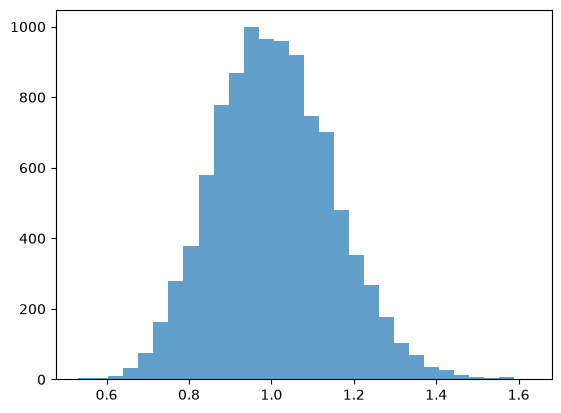

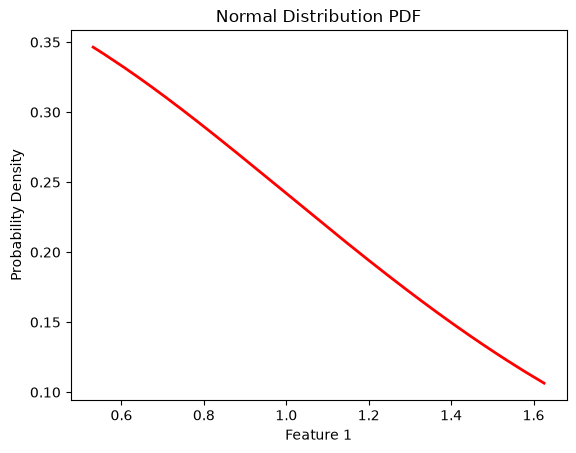

-0.005025769284283557
1.0063343440339643


In [11]:
import random
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

rng = np.random.default_rng(seed=42)  # Set a random seed for reproducibility

mu = 0  # Mean of the normal distribution
sigma = 1  # Standard deviation of the normal distribution
population_data = rng.normal(loc=mu, scale=sigma, size=100000)
plt.scatter(population_data, np.zeros_like(population_data), alpha=0.5)  # Scatter plot of the population data
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Population Data Visualization")
plt.show()

def plot_hist_curve(data, bins=10):
    plt.hist(data, bins=bins, alpha=0.7)  # Histogram of the data
    plt.show()

    x = np.sort(data)  # Sort the population data for plotting the PDF
    y = norm.pdf(x, mu, sigma)  # Probability density function of the normal distribution
    plt.plot(x, y, 'r-', lw=2)  # Plot the PDF
    plt.xlabel("Feature 1")
    plt.ylabel("Probability Density")
    plt.title("Normal Distribution PDF")
    plt.show()
    return np.array([x, y])  # Return the sorted data and corresponding PDF values

sample_size = 100  # Size of each sample
num_samples = 10000  # Number of samples to draw

sample_means = []
sample_variances = []
for _ in range(num_samples):
    sample_data = rng.choice(population_data, size=sample_size, replace=True)  # Draw a random sample with replacement
    sample_mean = np.mean(sample_data)  # Calculate the mean of the sample
    sample_variance = np.var(sample_data, ddof=1)  # Calculate the variance of the sample
    sample_means.append(sample_mean)  # Store the sample mean
    sample_variances.append(sample_variance)  # Store the sample variance

plot_hist_curve(population_data, bins=30)  # Plot histogram and PDF of the population data
plot_hist_curve(sample_means, bins=30)  # Plot histogram and PDF of sample means
plot_hist_curve(sample_variances, bins=30)  # Plot histogram and PDF of sample variances

print(np.mean(sample_means))  # Print the mean of the sample means
print(np.mean(sample_variances))  # Print the mean of the sample variances
